In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
import torch as tc
import sys
sys.path.append(os.path.dirname(os.path.abspath('')))
from src.paths import get_results_dir
RESULTS_DIR, DATA_DIR = get_results_dir()

In [ ]:
full = np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/full.npy")
noisy = np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/noisy.npy")
params = np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/params.npy", allow_pickle=True)

full_FT = np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/full_FT.npy", allow_pickle=True)
noisy_FT = tc.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/noisy_FT.pt")
params_FT = np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/params_FT.npy", allow_pickle=True)

## Saving

In [ ]:
save_path = DATA_DIR + "/hier-lorenz_preprocessed/"
seq_len = 275
for subject in range(64):
        subject_save_path = os.path.join(save_path, str(subject), "observations")
        all_time_series_dim = [noisy[subject, i*seq_len:(i+1)*seq_len] for i in range(noisy.shape[1]//seq_len)]
        #os.makedirs(subject_save_path, exist_ok=True)
        #with open(f"{subject_save_path}/noisy.pkl", "wb") as f:
        #        pickle.dump(all_time_series_dim, f)

In [ ]:
save_path = DATA_DIR + "/hier-lorenz_preprocessed_FT/"
seq_len = 300
for subject in range(64):
        subject_save_path = os.path.join(save_path, str(subject), "observations")
        all_time_series_dim = [noisy_FT[subject, i*seq_len:(i+1)*seq_len] for i in range(noisy_FT.shape[1]//seq_len)]


        os.makedirs(subject_save_path, exist_ok=True)
        with open(f"{subject_save_path}/noisy_FT.pkl", "wb") as f:
                pickle.dump(all_time_series_dim, f)

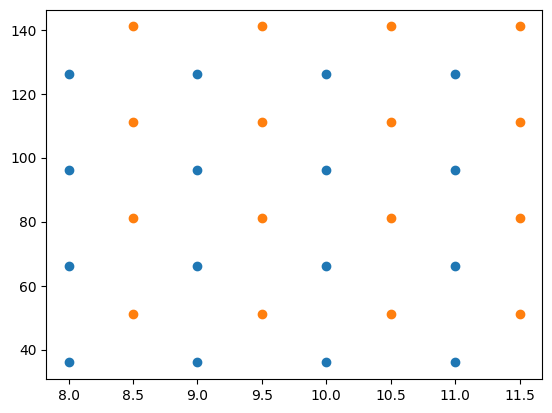

In [ ]:
a = np.unique([[params[i]["sigma"], params[i]["rho"]] for i in range(len(params))], axis=0)
plt.scatter(a[:, 0], a[:, 1])
a = np.unique([[params_FT["s"][i].cpu(), params_FT["r"][i].cpu()] for i in range(len(params_FT["s"]))], axis=0)
plt.scatter(a[:, 0], a[:, 1])


In [ ]:
params

array([{'sigma': 8.0, 'rho': 36.0, 'beta': 1.0},
       {'sigma': 9.0, 'rho': 36.0, 'beta': 1.0},
       {'sigma': 10.0, 'rho': 36.0, 'beta': 1.0},
       {'sigma': 11.0, 'rho': 36.0, 'beta': 1.0},
       {'sigma': 8.0, 'rho': 36.0, 'beta': 2.0},
       {'sigma': 9.0, 'rho': 36.0, 'beta': 2.0},
       {'sigma': 10.0, 'rho': 36.0, 'beta': 2.0},
       {'sigma': 11.0, 'rho': 36.0, 'beta': 2.0},
       {'sigma': 8.0, 'rho': 36.0, 'beta': 3.0},
       {'sigma': 9.0, 'rho': 36.0, 'beta': 3.0},
       {'sigma': 10.0, 'rho': 36.0, 'beta': 3.0},
       {'sigma': 11.0, 'rho': 36.0, 'beta': 3.0},
       {'sigma': 8.0, 'rho': 36.0, 'beta': 4.0},
       {'sigma': 9.0, 'rho': 36.0, 'beta': 4.0},
       {'sigma': 10.0, 'rho': 36.0, 'beta': 4.0},
       {'sigma': 11.0, 'rho': 36.0, 'beta': 4.0},
       {'sigma': 8.0, 'rho': 66.0, 'beta': 1.0},
       {'sigma': 9.0, 'rho': 66.0, 'beta': 1.0},
       {'sigma': 10.0, 'rho': 66.0, 'beta': 1.0},
       {'sigma': 11.0, 'rho': 66.0, 'beta': 1.0},
       {'s

In [ ]:
params_FT

{'s': tensor([ 8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000,
          8.5000,  9.5000, 10.5000, 11.5000,  8.5000,  9.5000, 10.5000, 11.5000],
        device='cuda:1'),
 'r': tensor([ 51.,  51.,  51.,  51.,  51.,  51.,  51.,  51.,  51.,  51.,  51.,  51.,
          51.,  51.,  51.,  51.,  81.,  81.,  81.,  81.,  81.,  81.,  81.,  81.,
          81.,  81.,  81.,  81.,  81.,  81.,  81.,  81., 111., 111., 111., 111.,
         111., 111., 111., 111., 111., 111., 111., 111., 111., 111., 111